In [2]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from src.eval import evaluate_and_log, compute_metrics
from src.features_freq import FREQ_COLS

P = ROOT / "data" / "processed"
THR = 0.47  

In [3]:
test = pd.read_csv(P / "test_clean.csv")
test = test.merge(pd.read_csv(P / "test_freq.csv"), on=["record", "minute"], validate="1:1")

med = pd.read_csv(P / "train_freq.csv")[FREQ_COLS].median()     # TRAINING medians
test[FREQ_COLS] = test[FREQ_COLS].fillna(med)

test = test.sort_values(["record", "minute"]).reset_index(drop=True)
FREQ_CTX = [f"{c}_ctx5" for c in FREQ_COLS]
test[FREQ_CTX] = test.groupby("record")[FREQ_COLS].transform(
    lambda s: s.rolling(5, center=True, min_periods=1).mean())

BASE = ["rr_mean", "rr_sdnn", "rr_rmssd", "rr_pnn50", "rr_min", "rr_max", "rr_range"]
Z = [c + "_z" for c in BASE]
CTX = [c + "_ctx" for c in Z]
FEATS = Z + CTX + FREQ_COLS + FREQ_CTX          # set E+
print(test.shape)

(16561, 45)


In [5]:
model = joblib.load(ROOT / "models" / "final_xgb.joblib")
test["y_prob"] = model.predict_proba(test[FEATS])[:, 1]

m_test = evaluate_and_log(test, test["y_prob"].to_numpy(), model_name="xgb_tuned_E+",
                          split_type="test", threshold=THR,
                          config={"family": "ML", "features": "E+"}, use_wandb=False)

[test | xgb_tuned_E+] Acc=0.8644 Sens=0.8575 Spec=0.8689 F1=0.8328 AUC=0.9348 (thr=0.47, PatAcc=0.857)


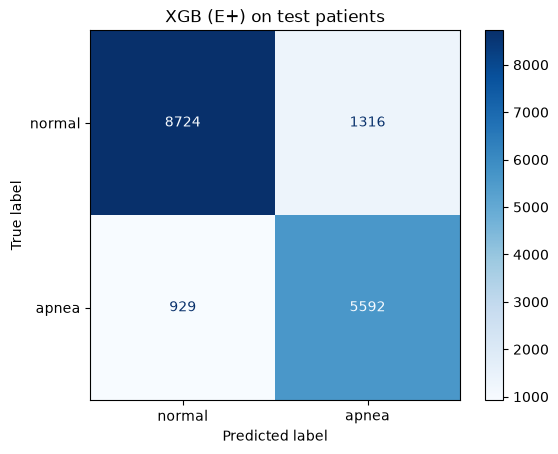

In [6]:
test["y_pred"] = (test["y_prob"] >= THR).astype(int)
ConfusionMatrixDisplay(confusion_matrix(test["label"], test["y_pred"]),
                       display_labels=["normal", "apnea"]).plot(cmap="Blues")
plt.title("XGB (E+) on test patients"); plt.show()

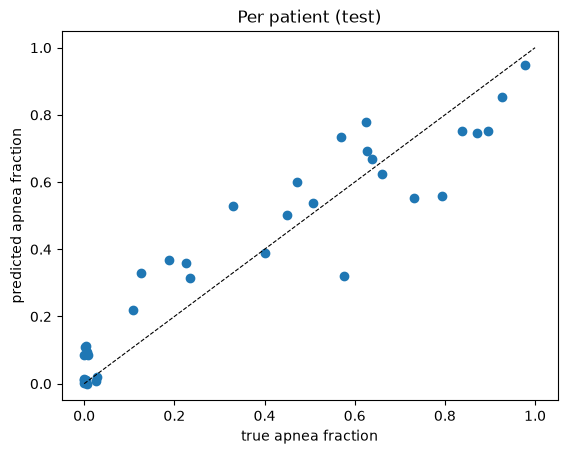

,true,pred,acc
record,,,
x13,0.577,0.320,0.704
x32,0.794,0.559,0.757
x01,0.731,0.554,0.776
x21,0.235,0.316,0.786
x14,0.896,0.751,0.794
x16,0.126,0.330,0.796
x10,0.189,0.367,0.798
x30,0.638,0.667,0.798


In [7]:
per_rec = test.groupby("record").agg(true=("label", "mean"), pred=("y_pred", "mean"),
                                     acc=("label", lambda s: (s == test.loc[s.index, "y_pred"]).mean()))
plt.scatter(per_rec.true, per_rec.pred)
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("true apnea fraction"); plt.ylabel("predicted apnea fraction")
plt.title("Per patient (test)"); plt.show()

per_rec.sort_values("acc").head(8).round(3)        # worst patients

ml dl comparison

In [8]:
dl = pd.read_csv(ROOT / "reports" / "preds" / "test_cnn_bigru_rredr_3m.csv")
m_dl = compute_metrics(dl["label"], dl["y_prob"], dl["record"], threshold=0.475)

pd.DataFrame({"ML: XGB (E+)": m_test, "DL: CNN-BiGRU (RR+EDR, 3 min)": m_dl}).round(4)

,ML: XGB (E+),"DL: CNN-BiGRU (RR+EDR, 3 min)"
threshold,0.4700,0.4750
accuracy,0.8644,0.9108
sensitivity,0.8575,0.9040
specificity,0.8689,0.9151
f1,0.8328,0.8886
roc_auc,0.9348,0.9694
patient_frac_mae,0.0925,0.0518
patient_screen_acc,0.8571,1.0000
